In [6]:
%pip uninstall -y torch torchvision torchaudio

Found existing installation: torch 2.14.1+cu130
Uninstalling torch-2.14.1+cu130:
  Successfully uninstalled torch-2.14.1+cu130
Found existing installation: torchvision 0.29.1+cu130
Uninstalling torchvision-0.29.1+cu130:
  Successfully uninstalled torchvision-0.29.1+cu130
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.
You can safely remove it manually.


In [ ]:
%pip install torch==2.7.1 torchvision==0.22.1 torchaudio==2.7.1 --index-url https://download.pytorch.org/whl/cu128 --timeout 1000

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
else:
    print("Running on CPU")

PyTorch: 2.7.1+cu128
CUDA available: True
CUDA version: 12.8
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU count: 1


In [2]:
import os, io, json, math, glob, tarfile, random, time as time_mod, warnings
from pathlib import Path
from datetime import date, timedelta
import numpy as np
import scipy.ndimage as ndi
import torch, torch.nn as nn, torch.nn.functional as F
import rasterio, rasterio.features
from rasterio.crs import CRS
from rasterio.enums import Resampling
from rasterio.transform import from_origin, array_bounds
from rasterio.vrt import WarpedVRT
from rasterio.warp import calculate_default_transform, reproject
from pyproj import Transformer
warnings.filterwarnings("ignore")

# ---------------- paths ----------------
BASE_DIR  = Path(r"C:\NIT KKR\after placement\iit mandi hackathon\dataset")
TRAIN_DIR = BASE_DIR / "train_grd"
VAL_DIR   = BASE_DIR / "val_grd"        # optional; if missing, 10% of train shards are held out
TEST_DIR  = BASE_DIR / "test_grd"
OUT_DIR   = BASE_DIR.parent / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- Kuro Siwo tar layout (verify in Cell 3) ----------------
CHANNEL_KEYS = ["sec1_vv", "sec1_vh", "sec2_vv", "sec2_vh", "flood_vv", "flood_vh", "dem"]
MASK_KEY, VALID_KEY = "mask", "valid_mask"   # labels: 0 no water, 1 permanent water, 2 flood
DEM_VALID_RANGE = (-430, 9000)   # CHANGED: Dead-Sea-to-Everest plausible elevation range; outside this is bad/nodata DEM, not real terrain

# ---------------- training ----------------
SEED, EPOCHS, BATCH, LR = 42, 15, 16, 3e-4
STATS_SAMPLES, CLIP, SHUFFLE_BUF = 1500, 5.0, 512
SMOOTH_WINDOW, PATIENCE, POS_WEIGHT_CAP = 3, 5, 8.0   # CHANGED: smoothed checkpoint selection, early stopping, imbalance weighting
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True   # CHANGED: minor speed win
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---------------- case study ----------------
EVENT_DATE = "2026-08-26"
AOI_BBOX = (85.15, 27.93, 85.45, 28.25)      # lon_min, lat_min, lon_max, lat_max (Syabrubesi -> Betrawati). Edit as needed.
GRID_RES = 10
PRE_WINDOW_DAYS, POST_WINDOW_DAYS, POST_MIN_OFFSET_DAYS = 60, 20, 1
# post-processing rules (fixed a priori, NOT tuned on EMSR927)
PRE_DARK_DB, SLOPE_MAX_DEG, MIN_AREA_PX = -18.0, 35.0, 15   # CHANGED: SLOPE_MAX_DEG 20 -> 35; 20° discards plausible flood pixels on steep Himalayan valley walls
BASELINE_DROP_DB, BASELINE_POST_DB = -3.0, -15.0
# OSM / analysis
OSM_TIME = "2026-08-25"                       # pre-event snapshot only
SCENARIOS = {"inside_flood": 0, "buffer_25m": 25}   # road-disable distance in metres
PRIMARY_SCENARIO = "inside_flood"
SNAP_MAX_M = 500
RESPONSE_POINTS = []                          # [(name, lon, lat), ...] extra rescue/response locations

ATTR = {
    "sentinel": "Contains modified Copernicus Sentinel data 2026.",
    "dem": "Produced using Copernicus WorldDEM-30 © DLR e.V. 2010–2014 and © Airbus Defence and Space GmbH 2014–2018 provided under COPERNICUS by the European Union and ESA; all rights reserved.",
    "osm": "© OpenStreetMap contributors.",
    "kuro": "Kuro Siwo: Bountos et al., 2024 (Kuro Siwo repository).",
}
DISCLAIMER = ("Educational prototype, not an operational emergency-response system. Sentinel revisit gaps, AI false "
              "positives/negatives, possible poor transfer from Kuro Siwo to Himalayan terrain, incomplete OSM, and "
              "connectivity estimates that do not guarantee physical passability all apply.")

# ---------------- json / results ----------------
def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
def load_json(path):
    with open(path) as f: return json.load(f)
RES_PATH = OUT_DIR / "results.json"
R = load_json(RES_PATH) if RES_PATH.exists() else {}
def save_results(): save_json(R, RES_PATH)

# ---------------- tar shard reader (no webdataset, Windows-safe) ----------------
def iter_shard(path):
    with tarfile.open(str(path)) as tf:
        cur_key, cur = None, {}
        for m in tf:
            if not m.isfile(): continue
            name = os.path.basename(m.name)
            if "." not in name: continue
            stem, ext = name.split(".", 1)
            if not ext.endswith(".npy"): continue
            if stem != cur_key:
                if cur: yield cur_key, cur
                cur_key, cur = stem, {}
            cur[ext[:-4]] = np.load(io.BytesIO(tf.extractfile(m).read()), allow_pickle=False)
        if cur: yield cur_key, cur

class TarShardDataset(torch.utils.data.IterableDataset):
    def __init__(self, shards, transform, shuffle=False, buffer=SHUFFLE_BUF, seed=0, limit=None):
        self.shards = [str(s) for s in shards]; self.transform = transform
        self.shuffle, self.buffer, self.seed, self.limit, self.epoch = shuffle, buffer, seed, limit, 0
    def __iter__(self):
        rng = random.Random(self.seed + self.epoch); self.epoch += 1
        shards = list(self.shards)
        if self.shuffle: rng.shuffle(shards)
        buf, n = [], 0
        for sh in shards:
            for _, sample in iter_shard(sh):
                item = self.transform(sample)
                if self.shuffle:
                    buf.append(item)
                    if len(buf) >= self.buffer:
                        j = rng.randrange(len(buf)); buf[j], buf[-1] = buf[-1], buf[j]
                        yield buf.pop(); n += 1
                else:
                    yield item; n += 1
                if self.limit and n >= self.limit: return
        rng.shuffle(buf)
        for it in buf:
            if self.limit and n >= self.limit: return
            yield it; n += 1

# ---------------- preprocessing (shared by training and Himalayan inference) ----------------
def sample_to_raw(sample):
    missing = [k for k in CHANNEL_KEYS + [MASK_KEY] if k not in sample]
    if missing: raise KeyError(f"Missing keys {missing}; available: {list(sample.keys())}")
    chans = [np.squeeze(sample[k]).astype(np.float32) for k in CHANNEL_KEYS]
    raw = np.stack(chans, 0)
    mask = np.squeeze(sample[MASK_KEY]).astype(np.int16)
    valid = np.squeeze(sample[VALID_KEY]).astype(bool) if VALID_KEY in sample else ((mask >= 0) & (mask <= 2))
    dem = raw[CHANNEL_KEYS.index("dem")]   # CHANGED: exclude physically-impossible DEM pixels from training/stats
    valid = valid & (dem >= DEM_VALID_RANGE[0]) & (dem <= DEM_VALID_RANGE[1])
    return raw, mask, valid

def detect_sar_mode(vals):
    v = vals[np.isfinite(vals)]
    med = float(np.median(v))
    if np.percentile(v, 1) >= 0 and med < 10: return "linear", med
    if med < -5: return "db", med
    if med < 0: return "log10", med
    raise ValueError(f"Cannot infer SAR scale (median={med})")

def raw_to_domain(raw, mode):
    x = raw.copy()
    if mode == "linear":
        s = x[:6]
        x[:6] = np.where(s > 0, 10 * np.log10(np.where(s > 0, s, 1)), np.nan)
    return x

def lin_to_domain(lin, mode):            # for Himalayan linear-power rasters
    out = np.full(lin.shape, np.nan, np.float32); ok = lin > 0
    out[ok] = np.log10(lin[ok]) if mode == "log10" else 10 * np.log10(lin[ok])
    return out

def normalize(x, stats):
    m = np.array(stats["mean"], np.float32)[:, None, None]
    s = np.array(stats["std"], np.float32)[:, None, None]
    z = (x - m) / (s + 1e-6)
    z = np.nan_to_num(z, nan=0.0, posinf=0.0, neginf=0.0)
    return np.clip(z, -CLIP, CLIP).astype(np.float32)

def make_transform(stats):
    mode = stats["sar_mode"]
    def tf(sample):
        raw, mask, valid = sample_to_raw(sample)
        x = raw_to_domain(raw, mode)
        valid = valid & np.isfinite(x).all(0)
        z = normalize(x, stats)
        y = (mask == 2).astype(np.float32)
        return (torch.from_numpy(z), torch.from_numpy(y[None]), torch.from_numpy(valid.astype(np.float32)[None]))
    return tf

# ---------------- model / loss / metrics ----------------
def build_model(pretrained=True):
    import segmentation_models_pytorch as smp
    try:
        m = smp.Unet("resnet18", encoder_weights="imagenet" if pretrained else None, in_channels=7, classes=1)
    except Exception as e:
        print("Pretrained weights unavailable, using random init:", e)
        m = smp.Unet("resnet18", encoder_weights=None, in_channels=7, classes=1)
    return m.to(DEVICE)

def masked_loss(logits, y, v, pos_weight=None):   # CHANGED: optional pos_weight for the ~7% positive-pixel imbalance
    pw = None if pos_weight is None else torch.tensor(float(pos_weight), device=logits.device)
    bce = F.binary_cross_entropy_with_logits(logits, y, reduction="none", pos_weight=pw)
    bce = (bce * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    inter = (p * y).sum(); den = p.sum() + (y * v).sum()
    return bce + (1 - (2 * inter + 1) / (den + 1))

def tta_predict_batch(model, xb):   # CHANGED: new helper — 4-way flip-averaged test-time augmentation
    outs = []
    for dims in [None, (-1,), (-2,), (-1, -2)]:
        xt = xb if dims is None else xb.flip(dims)
        with torch.no_grad():
            p = torch.sigmoid(model(xt))
        outs.append(p if dims is None else p.flip(dims))
    return torch.stack(outs).mean(0)

THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.05), 2)
def counts_to_metrics(tp, fp, fn):
    e = 1e-9
    return dict(iou=tp/(tp+fp+fn+e), f1=2*tp/(2*tp+fp+fn+e), precision=tp/(tp+fp+e), recall=tp/(tp+fn+e),
                tp=int(tp), fp=int(fp), fn=int(fn))

@torch.no_grad()
def evaluate(model, loader, thresholds=THRESHOLDS, tta=False):   # CHANGED: added tta flag
    model.eval()
    th = torch.tensor(thresholds, device=DEVICE, dtype=torch.float32).view(-1, 1)
    T = len(thresholds)
    tp = torch.zeros(T, dtype=torch.float64, device=DEVICE); fp = torch.zeros_like(tp); fn = torch.zeros_like(tp)
    for x, y, v in loader:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        p = tta_predict_batch(model, x) if tta else torch.sigmoid(model(x))
        m = v > 0.5
        pv = p[m].view(1, -1); yv = (y[m] > 0.5).view(1, -1)
        pred = pv >= th
        tp += (pred & yv).sum(1).double(); fp += (pred & ~yv).sum(1).double(); fn += ((~pred) & yv).sum(1).double()
    return [dict(threshold=float(t), **counts_to_metrics(float(a), float(b), float(c)))
            for t, a, b, c in zip(thresholds, tp.cpu(), fp.cpu(), fn.cpu())]

# ---------------- geo helpers ----------------
def make_grid(bbox, res):
    lon0, lat0, lon1, lat1 = bbox
    epsg = 32600 + int(((lon0 + lon1) / 2 + 180) // 6) + 1
    tr = Transformer.from_crs(4326, epsg, always_xy=True)
    xs, ys = tr.transform([lon0, lon1, lon0, lon1], [lat0, lat0, lat1, lat1])
    xmin, xmax = math.floor(min(xs)/res)*res, math.ceil(max(xs)/res)*res
    ymin, ymax = math.floor(min(ys)/res)*res, math.ceil(max(ys)/res)*res
    return dict(epsg=epsg, crs=CRS.from_epsg(epsg), transform=from_origin(xmin, ymax, res, res),
                width=int((xmax-xmin)/res), height=int((ymax-ymin)/res), bounds=(xmin, ymin, xmax, ymax), res=res)

def read_to_grid(href, grid, resampling=Resampling.bilinear):
    env = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.tiff",
               GDAL_HTTP_MAX_RETRY="5", GDAL_HTTP_RETRY_DELAY="2")
    with rasterio.Env(**env):
        with rasterio.open(href) as src:
            with WarpedVRT(src, crs=grid["crs"], transform=grid["transform"], width=grid["width"],
                           height=grid["height"], resampling=resampling, src_nodata=src.nodata,
                           nodata=np.nan, dtype="float32") as vrt:
                return vrt.read(1)

def save_geotiff(path, arr, grid, nodata=None, dtype=None):
    a = arr if arr.ndim == 3 else arr[None]
    with rasterio.open(path, "w", driver="GTiff", height=a.shape[1], width=a.shape[2], count=a.shape[0],
                       dtype=dtype or a.dtype, crs=grid["crs"], transform=grid["transform"],
                       nodata=nodata, compress="deflate") as dst:
        dst.write(a.astype(dtype or a.dtype))

def read_tif(path):
    with rasterio.open(path) as ds:
        arr = ds.read()
        grid = dict(epsg=ds.crs.to_epsg(), crs=ds.crs, transform=ds.transform, width=ds.width, height=ds.height,
                    bounds=tuple(ds.bounds), res=ds.res[0])
    return arr, grid

def to_wgs84(arr, grid, resampling=Resampling.bilinear):
    dst_t, w, h = calculate_default_transform(grid["crs"], "EPSG:4326", grid["width"], grid["height"], *grid["bounds"])
    out = np.full((h, w), np.nan, np.float32)
    reproject(arr.astype(np.float32), out, src_transform=grid["transform"], src_crs=grid["crs"],
              dst_transform=dst_t, dst_crs="EPSG:4326", resampling=resampling, src_nodata=np.nan, dst_nodata=np.nan)
    return out, array_bounds(h, w, dst_t)    # (west, south, east, north)

print("Device:", DEVICE, "| outputs ->", OUT_DIR)

Device: cuda | outputs -> C:\NIT KKR\after placement\iit mandi hackathon\outputs


In [3]:
train_shards = sorted(TRAIN_DIR.glob("*.tar"))
if not train_shards: raise FileNotFoundError(f"No .tar in {TRAIN_DIR}")
print(len(train_shards), "train shards")

key0, s0 = next(iter_shard(train_shards[0]))
print("Sample id:", key0)
for k, v in s0.items():
    print(f"  {k:14s} shape={v.shape} dtype={v.dtype} min={np.nanmin(v):.4g} max={np.nanmax(v):.4g}")

vals = []
for i, (_, s) in enumerate(iter_shard(train_shards[0])):
    if i >= 64: break
    raw, mask, valid = sample_to_raw(s)
    vals.append(raw[:6, valid][:, ::97].ravel())
SAR_MODE, med = detect_sar_mode(np.concatenate(vals))
print(f"SAR scale detected: {SAR_MODE} (median raw value {med:.3f})")
print("Mask labels in first sample:", np.unique(np.squeeze(s0[MASK_KEY])))

n = np.zeros(7); sm = np.zeros(7); sq = np.zeros(7); pos = 0; tot = 0; cnt = 0
for sh in train_shards:
    for _, s in iter_shard(sh):
        raw, mask, valid = sample_to_raw(s)
        x = raw_to_domain(raw, SAR_MODE)
        v = valid & np.isfinite(x).all(0)
        xv = x[:, v].astype(np.float64)
        n += xv.shape[1]; sm += xv.sum(1); sq += (xv ** 2).sum(1)
        pos += int(((mask == 2) & v).sum()); tot += int(v.sum()); cnt += 1
        if cnt >= STATS_SAMPLES: break
    if cnt >= STATS_SAMPLES: break
mean = sm / n; std = np.sqrt(np.maximum(sq / n - mean ** 2, 1e-12))
STATS = dict(sar_mode=SAR_MODE, mean=mean.tolist(), std=std.tolist(), channel_keys=CHANNEL_KEYS,
             clip=CLIP, flood_fraction=pos / max(tot, 1), samples_used=cnt)
save_json(STATS, OUT_DIR / "norm_stats.json")
print("mean:", np.round(mean, 3)); print("std :", np.round(std, 3))
print(f"Flood pixel fraction: {pos / max(tot, 1):.4%}  (very low means class imbalance, hence the Dice loss)")

5 train shards
Sample id: 000000
  flood_vv       shape=(1, 224, 224) dtype=float32 min=0.003217 max=1.032
  flood_vh       shape=(1, 224, 224) dtype=float32 min=0.001893 max=12.24
  sec1_vv        shape=(1, 224, 224) dtype=float32 min=0.01484 max=0.9057
  sec1_vh        shape=(1, 224, 224) dtype=float32 min=0.001854 max=1.982
  sec2_vv        shape=(1, 224, 224) dtype=float32 min=0.01018 max=0.7871
  sec2_vh        shape=(1, 224, 224) dtype=float32 min=0.002129 max=1.42
  dem            shape=(1, 224, 224) dtype=float32 min=104.1 max=137.9
  mask           shape=(1, 224, 224) dtype=float32 min=0 max=2
  valid_mask     shape=(1, 224, 224) dtype=float32 min=1 max=1
SAR scale detected: linear (median raw value 0.025)
Mask labels in first sample: [0. 2.]
mean: [-10.194 -17.222 -10.571 -17.637  -9.797 -16.36   74.978]
std : [ 3.941  3.868  4.12   4.095  4.43   4.204 85.293]
Flood pixel fraction: 7.2704%  (very low means class imbalance, hence the Dice loss)


train shards: 4 | val shards: 1
NOTE: very few shards available — if more Kuro Siwo shards exist, adding them will likely help generalization more than any hyperparameter change below.
Using BCE pos_weight=8.00 (flood pixels are 7.27% of valid pixels)
  ep1 batch50 loss 1.0642
  ep1 batch100 loss 0.8148
  ep1 batch150 loss 0.6823
  ep1 batch200 loss 0.4629
  ep1 batch250 loss 0.5566
  ep1 batch300 loss 0.5195
  ep1 batch350 loss 0.4278
  ep1 batch400 loss 0.4681
  ep1 batch450 loss 0.5976
  ep1 batch500 loss 1.1022
  ep1 batch550 loss 0.8495
  ep1 batch600 loss 0.5787
  ep1 batch650 loss 0.5507
  ep1 batch700 loss 1.0447
  ep1 batch750 loss 0.3891
  ep1 batch800 loss 0.4583
  ep1 batch850 loss 0.4419
  ep1 batch900 loss 0.5704
  ep1 batch950 loss 0.8521
  ep1 batch1000 loss 0.7960
  ep1 batch1050 loss 0.3634
  ep1 batch1100 loss 0.6226
  ep1 batch1150 loss 0.7271
  ep1 batch1200 loss 0.6109
Epoch 1/15 loss 0.6764 | val IoU 0.6073 @thr 0.8 | smoothed 0.6073 | 922s
  ep2 batch50 loss 0.9

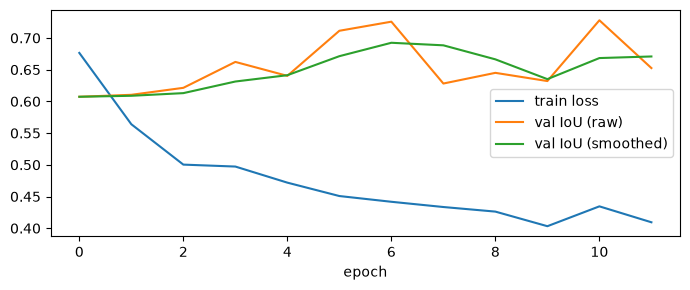

In [4]:
import matplotlib.pyplot as plt
STATS = load_json(OUT_DIR / "norm_stats.json"); TF = make_transform(STATS)

all_shards = sorted(TRAIN_DIR.glob("*.tar"))
val_shards = sorted(VAL_DIR.glob("*.tar")) if VAL_DIR.exists() else []
if val_shards:
    train_shards = all_shards
else:
    sh = all_shards[:]; random.Random(SEED).shuffle(sh)
    n_val = max(1, round(0.1 * len(sh))); val_shards, train_shards = sh[:n_val], sh[n_val:]
print(f"train shards: {len(train_shards)} | val shards: {len(val_shards)}")
if len(train_shards) + len(val_shards) < 20:
    print("NOTE: very few shards available — if more Kuro Siwo shards exist, adding them will likely help "
          "generalization more than any hyperparameter change below.")

train_loader = torch.utils.data.DataLoader(TarShardDataset(train_shards, TF, shuffle=True, seed=SEED),
                                           batch_size=BATCH, num_workers=0)
val_loader = torch.utils.data.DataLoader(TarShardDataset(val_shards, TF, shuffle=False),
                                         batch_size=BATCH, num_workers=0)

def augment(x, y, v):
    if random.random() < 0.5: x, y, v = x.flip(-1), y.flip(-1), v.flip(-1)
    if random.random() < 0.5: x, y, v = x.flip(-2), y.flip(-2), v.flip(-2)
    k = random.randint(0, 3)
    if k: x, y, v = [torch.rot90(t, k, (-2, -1)) for t in (x, y, v)]
    return x, y, v

# CHANGED: class-imbalance-aware loss weight, derived from the measured flood pixel fraction
POS_WEIGHT = min(POS_WEIGHT_CAP, (1 - STATS["flood_fraction"]) / max(STATS["flood_fraction"], 1e-6))
print(f"Using BCE pos_weight={POS_WEIGHT:.2f} (flood pixels are {STATS['flood_fraction']:.2%} of valid pixels)")

model = build_model(pretrained=True)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
use_amp = DEVICE.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# CHANGED: checkpoint/select on a smoothed val IoU + early stopping, instead of one noisy epoch's IoU
history, iou_track = [], []
best_smooth_iou, no_improve = -1.0, 0

for ep in range(1, EPOCHS + 1):
    model.train(); run, nb, t0 = 0.0, 0, time_mod.time()
    for x, y, v in train_loader:
        x, y, v = augment(x.to(DEVICE), y.to(DEVICE), v.to(DEVICE))
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=use_amp):
            logits = model(x)
        loss = masked_loss(logits.float(), y, v, pos_weight=POS_WEIGHT)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # CHANGED: stabilizes the loss spikes seen in training
        scaler.step(opt); scaler.update()
        run += loss.item(); nb += 1
        if nb % 50 == 0: print(f"  ep{ep} batch{nb} loss {loss.item():.4f}")
    sched.step()
    vm = evaluate(model, val_loader)
    bm = max(vm, key=lambda d: d["iou"])
    iou_track.append(bm["iou"])
    smooth_iou = float(np.mean(iou_track[-SMOOTH_WINDOW:]))
    history.append(dict(epoch=ep, train_loss=run / max(nb, 1), val_best_iou=bm["iou"],
                        val_best_thr=bm["threshold"], val_smooth_iou=smooth_iou))
    print(f"Epoch {ep}/{EPOCHS} loss {run/max(nb,1):.4f} | val IoU {bm['iou']:.4f} @thr {bm['threshold']} "
         f"| smoothed {smooth_iou:.4f} | {time_mod.time()-t0:.0f}s")
    if smooth_iou > best_smooth_iou:
        best_smooth_iou = smooth_iou; no_improve = 0
        torch.save(model.state_dict(), OUT_DIR / "best_model.pth")
    else:
        no_improve += 1
    if no_improve >= PATIENCE:
        print(f"No improvement in smoothed val IoU for {PATIENCE} epochs — stopping early at epoch {ep}.")
        break

model.load_state_dict(torch.load(OUT_DIR / "best_model.pth", map_location=DEVICE, weights_only=True))
vm = evaluate(model, val_loader); bm = max(vm, key=lambda d: d["iou"])
META = dict(threshold=bm["threshold"], val_metrics=bm, history=history, epochs=len(history), pos_weight=POS_WEIGHT)
save_json(META, OUT_DIR / "model_meta.json")
print("Chosen threshold:", META["threshold"], "| val metrics:", {k: round(v, 4) for k, v in bm.items() if isinstance(v, float)})

plt.figure(figsize=(7, 3))
plt.plot([h["train_loss"] for h in history], label="train loss")
plt.plot([h["val_best_iou"] for h in history], label="val IoU (raw)")
plt.plot([h["val_smooth_iou"] for h in history], label="val IoU (smoothed)")
plt.legend(); plt.xlabel("epoch"); plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=150); plt.show()

Kuro Siwo TEST @thr 0.5 (with TTA)
  iou      : 0.5910  (no-TTA: 0.5871)
  f1       : 0.7429  (no-TTA: 0.7398)
  precision: 0.6990  (no-TTA: 0.6936)
  recall   : 0.7928  (no-TTA: 0.7927)


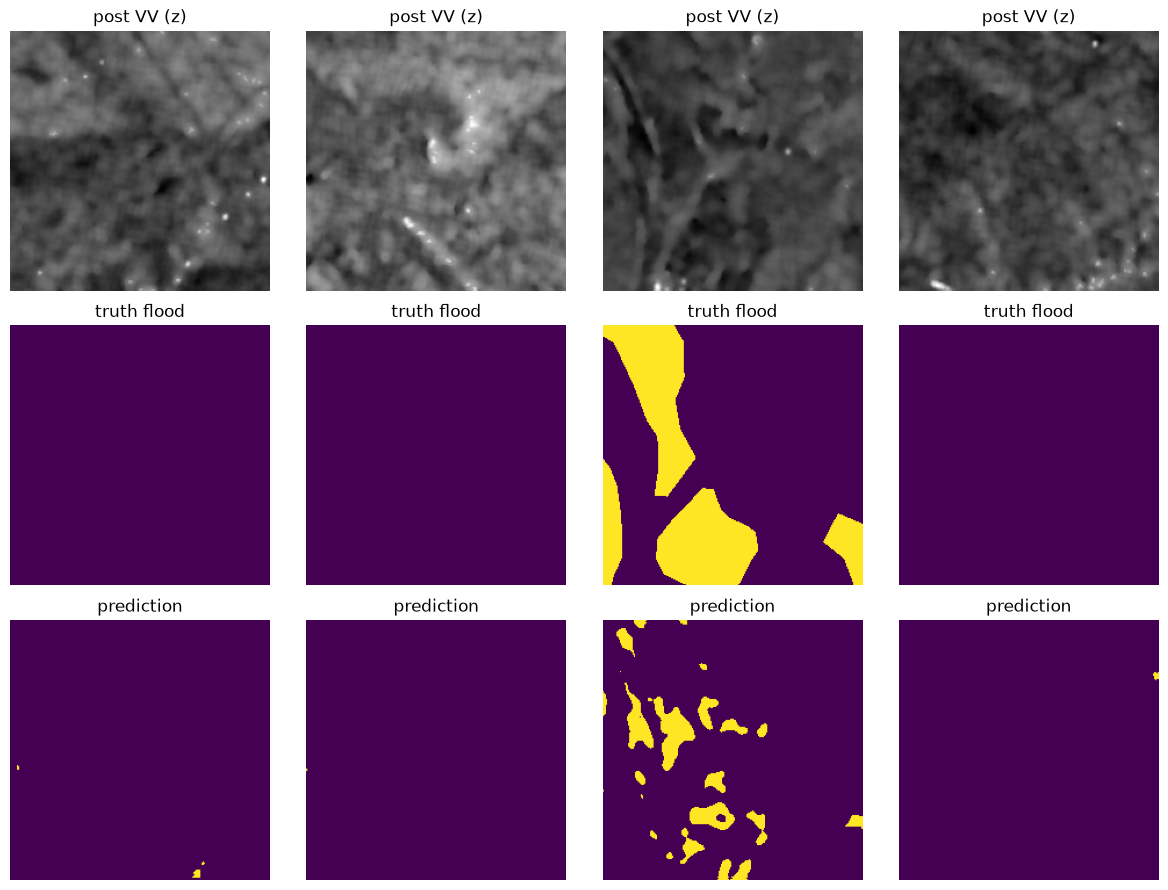

In [5]:
STATS = load_json(OUT_DIR / "norm_stats.json"); META = load_json(OUT_DIR / "model_meta.json"); TF = make_transform(STATS)
model = build_model(False)
model.load_state_dict(torch.load(OUT_DIR / "best_model.pth", map_location=DEVICE, weights_only=True))

test_shards = sorted(TEST_DIR.glob("*.tar"))
if not test_shards: raise FileNotFoundError(f"No .tar in {TEST_DIR}")
test_loader = torch.utils.data.DataLoader(TarShardDataset(test_shards, TF), batch_size=BATCH, num_workers=0)

# CHANGED: report with and without test-time augmentation (4-way flip averaging) — no retraining needed
tm_plain = evaluate(model, test_loader, thresholds=np.array([0.5, META["threshold"]]), tta=False)
tm_tta   = evaluate(model, test_loader, thresholds=np.array([0.5, META["threshold"]]), tta=True)
chosen = tm_tta[1]
R["kuro_siwo_test"] = dict(threshold=chosen["threshold"], iou=chosen["iou"], f1=chosen["f1"],
                           precision=chosen["precision"], recall=chosen["recall"],
                           at_0p5=tm_tta[0], without_tta=tm_plain[1],
                           note="Held-out Kuro Siwo test (NOT Himalayan). TTA = flip-averaged inference.")
save_results()
print("Kuro Siwo TEST @thr", chosen["threshold"], "(with TTA)")
for k in ["iou", "f1", "precision", "recall"]: print(f"  {k:9s}: {chosen[k]:.4f}  (no-TTA: {tm_plain[1][k]:.4f})")

import matplotlib.pyplot as plt
model.eval(); xb, yb, vb = next(iter(test_loader))
with torch.no_grad(): pb = tta_predict_batch(model, xb.to(DEVICE)).cpu()
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for i in range(4):
    ax[0, i].imshow(xb[i, 4], cmap="gray"); ax[0, i].set_title("post VV (z)")
    ax[1, i].imshow(yb[i, 0]); ax[1, i].set_title("truth flood")
    ax[2, i].imshow(pb[i, 0] >= META["threshold"]); ax[2, i].set_title("prediction")
    for r in range(3): ax[r, i].axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "kuro_siwo_examples.png", dpi=130); plt.show()

In [6]:
from shapely.geometry import box, shape
from shapely.ops import unary_union
import planetary_computer as pc
from pystac_client import Client
import os
import time
import requests
from pathlib import Path

EVENT = date.fromisoformat(EVENT_DATE)
GRID = make_grid(AOI_BBOX, GRID_RES)
AOI = box(*AOI_BBOX)

print(
    f"Grid: EPSG:{GRID['epsg']} "
    f"{GRID['width']}x{GRID['height']} px @ {GRID_RES} m"
)

# Optional manual fallback
MANUAL_FILES = {}

S1_COLLECTION = "sentinel-1-rtc"  # CHANGED: exposed as a constant — also try "sentinel-1-grd" and compare,
                                   # since Kuro Siwo's radiometric processing level may match one better than the other

# ------------------------------------------------------------
# FIX: robust raster reader
# ------------------------------------------------------------

CACHE_DIR = Path(OUT_DIR) / "_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def read_to_grid_robust(href, grid, resampling=Resampling.bilinear, name="asset"):
    for attempt in range(3):
        try:
            with rasterio.open(href) as src:
                with WarpedVRT(
                    src,
                    crs=grid["crs"],
                    transform=grid["transform"],
                    width=grid["width"],
                    height=grid["height"],
                    resampling=resampling,
                    src_nodata=src.nodata,
                    nodata=np.nan,
                    dtype="float32"
                ) as vrt:
                    return vrt.read(1)

        except RasterioIOError as e:
            print(f"Remote read failed for {name}, retry {attempt+1}/3")
            time.sleep(2)

    local = CACHE_DIR / f"{name}.tif"

    if not local.exists():
        print(f"Downloading locally: {name}")
        r = requests.get(href, timeout=300)
        r.raise_for_status()
        local.write_bytes(r.content)

    print(f"Reading local copy: {name}")

    with rasterio.open(local) as src:
        with WarpedVRT(
            src,
            crs=grid["crs"],
            transform=grid["transform"],
            width=grid["width"],
            height=grid["height"],
            resampling=resampling,
            src_nodata=src.nodata,
            nodata=np.nan,
            dtype="float32"
        ) as vrt:
            return vrt.read(1)


def read_list(hrefs, resampling=Resampling.bilinear, prefix="asset"):
    out = None

    for i, h in enumerate(hrefs):
        a = read_to_grid_robust(
            h,
            GRID,
            resampling,
            f"{prefix}_{i}"
        )

        out = a if out is None else np.where(np.isnan(out), a, out)

    return out


def clean_lin(a):
    a = a.astype(np.float32).copy()
    a[~np.isfinite(a) | (a <= 0)] = np.nan
    return a


def clip_dem(a):   # CHANGED: new — drop physically-impossible elevation values before filling/using the DEM
    out = a.astype(np.float32).copy()
    out[(out < DEM_VALID_RANGE[0]) | (out > DEM_VALID_RANGE[1])] = np.nan
    return out


def fill_nan_nearest(a):
    if np.isnan(a).all():
        raise RuntimeError("DEM is all NaN")

    idx = ndi.distance_transform_edt(
        np.isnan(a),
        return_distances=False,
        return_indices=True
    )

    return a[tuple(idx)]


acq = {
    "event_date": EVENT_DATE,
    "aoi_bbox": AOI_BBOX
}

if MANUAL_FILES:

    bands = {
        k: read_to_grid_robust(p, GRID, name=k)
        for k, p in MANUAL_FILES.items()
    }

    pre1_vv, pre1_vh, pre2_vv, pre2_vh, post_vv, post_vh = [
        clean_lin(bands[k])
        for k in [
            "pre1_vv",
            "pre1_vh",
            "pre2_vv",
            "pre2_vh",
            "post_vv",
            "post_vh"
        ]
    ]

    dem = fill_nan_nearest(clip_dem(bands["dem"]))  # CHANGED
    acq["source"] = "manual files"

else:

    cat = Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=pc.sign_inplace
    )

    rng = (
        f"{EVENT - timedelta(days=PRE_WINDOW_DAYS)}"
        f"/"
        f"{EVENT + timedelta(days=POST_WINDOW_DAYS)}"
    )

    items = list(
        cat.search(
            collections=[S1_COLLECTION],  # CHANGED: was hardcoded "sentinel-1-rtc"
            bbox=AOI_BBOX,
            datetime=rng
        ).items()
    )

    print("S1 items found:", len(items))

    groups = {}

    for it in items:
        if "vv" not in it.assets or "vh" not in it.assets:
            continue

        k = (
            it.properties.get("sat:relative_orbit"),
            it.properties.get("sat:orbit_state"),
            it.datetime.date()
        )

        groups.setdefault(k, []).append(it)

    cov = lambda its: (
        unary_union([shape(i.geometry) for i in its])
        .intersection(AOI).area / AOI.area
    )

    groups = {
        k: v
        for k, v in groups.items()
        if cov(v) >= 0.95
    }

    tracks = {}

    for (orb, state, d), its in groups.items():
        tracks.setdefault((orb, state), []).append((d, its))

    cands = []

    for tr, lst in tracks.items():

        lst.sort(key=lambda t: t[0])

        pre = [t for t in lst if t[0] < EVENT]

        post = [
            t for t in lst
            if t[0] >= EVENT + timedelta(days=POST_MIN_OFFSET_DAYS)
        ]

        print("track", tr, "dates:", [str(t[0]) for t in lst])

        if len(pre) >= 2 and post:
            cands.append(
                dict(
                    track=tr,
                    pre=pre[-2:],
                    post=post[0],
                    delay=(post[0][0] - EVENT).days,
                    pre_gap=(EVENT - pre[-1][0]).days
                )
            )

    if not cands:
        raise RuntimeError(
            "No orbit track has >=2 pre-event and >=1 post-event scenes "
            "covering the AOI."
        )

    best = min(
        cands,
        key=lambda c: (c["delay"], c["pre_gap"])
    )

    (d1, its1), (d2, its2), (dp, itsp) = (
        best["pre"][0],
        best["pre"][1],
        best["post"]
    )

    print(
        f"Chosen track {best['track']}: "
        f"pre {d1}, {d2} | post {dp}"
    )

    rd = lambda its, a, name: clean_lin(
        read_list(
            [i.assets[a].href for i in its],
            prefix=name
        )
    )

    pre1_vv = rd(its1, "vv", "pre1_vv")
    pre1_vh = rd(its1, "vh", "pre1_vh")

    pre2_vv = rd(its2, "vv", "pre2_vv")
    pre2_vh = rd(its2, "vh", "pre2_vh")

    post_vv = rd(itsp, "vv", "post_vv")
    post_vh = rd(itsp, "vh", "post_vh")

    dem_items = list(
        cat.search(
            collections=["cop-dem-glo-30"],
            bbox=AOI_BBOX
        ).items()
    )

    dem = fill_nan_nearest(
        clip_dem(   # CHANGED
            read_list(
                [i.assets["data"].href for i in dem_items],
                prefix="dem"
            )
        )
    )

    acq.update(
        source=f"Microsoft Planetary Computer: {S1_COLLECTION}, cop-dem-glo-30",
        relative_orbit=best["track"][0],
        orbit_state=best["track"][1],
        pre_dates=[str(d1), str(d2)],
        post_date=str(dp),
        same_track=True,
        scene_ids=dict(
            pre1=[i.id for i in its1],
            pre2=[i.id for i in its2],
            post=[i.id for i in itsp]
        )
    )


STACK = np.stack(
    [
        pre1_vv,
        pre1_vh,
        pre2_vv,
        pre2_vh,
        post_vv,
        post_vh,
        dem
    ]
).astype(np.float32)

save_geotiff(
    OUT_DIR / "s1_stack_linear.tif",
    STACK,
    GRID,
    nodata=np.nan
)

R["acquisition"] = acq
save_results()

print(
    "Valid post-VV fraction:",
    float(np.isfinite(post_vv).mean())
)

Grid: EPSG:32645 2999x3588 px @ 10 m
S1 items found: 20
track (85, 'ascending') dates: ['2026-06-29', '2026-07-11', '2026-07-23', '2026-08-04', '2026-08-16', '2026-08-28', '2026-09-09']
track (19, 'descending') dates: ['2026-07-07', '2026-07-19', '2026-07-31', '2026-08-12', '2026-08-24', '2026-09-05']
Chosen track (85, 'ascending'): pre 2026-08-04, 2026-08-16 | post 2026-08-28
Valid post-VV fraction: 1.0


Running tiled inference...
[AI] raw=470px -> after permanent-water/shadow filter=470px -> after slope filter=470px -> after min-area filter=449px
[baseline] raw=46825px -> after permanent-water/shadow filter=45159px -> after slope filter=19956px -> after min-area filter=1384px
AI flood extent: 0.045 km² in 6 polygons | baseline: 0.138 km²


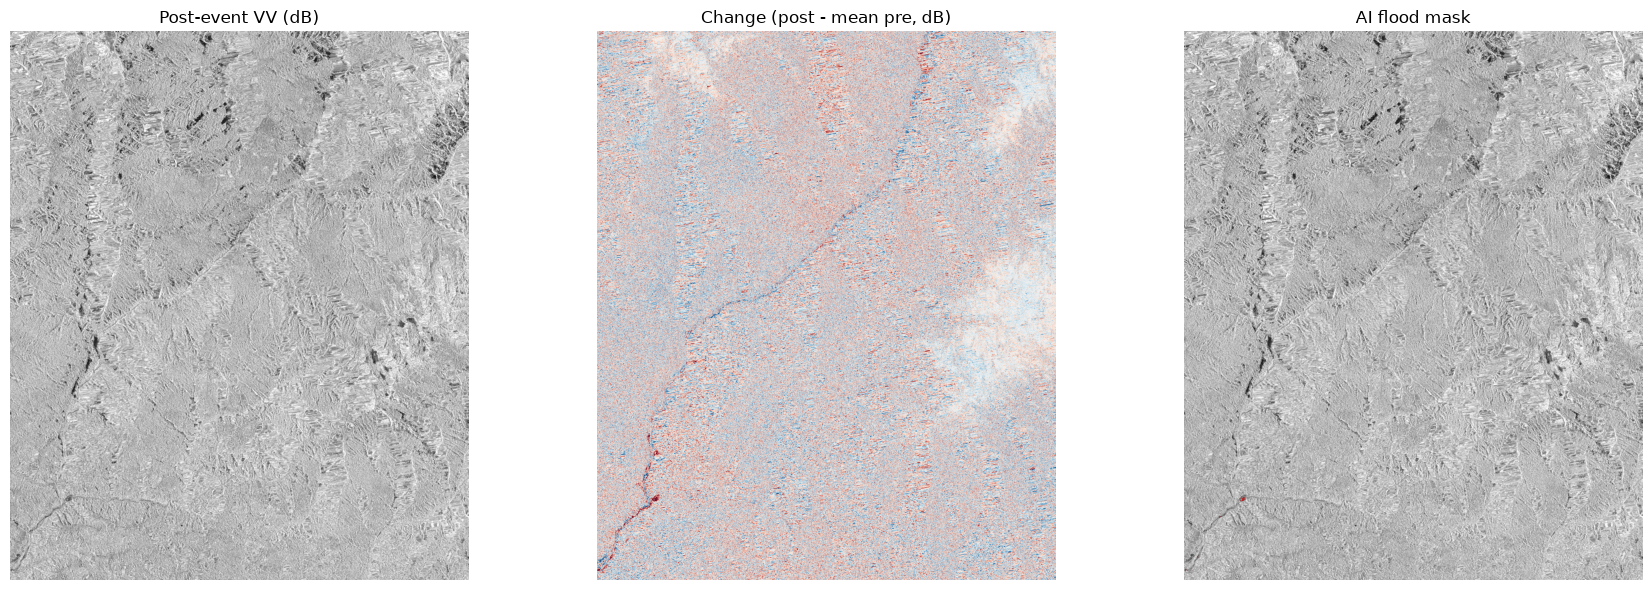

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt
STATS = load_json(OUT_DIR / "norm_stats.json"); META = load_json(OUT_DIR / "model_meta.json")
THR = META["threshold"]
model = build_model(False)
model.load_state_dict(torch.load(OUT_DIR / "best_model.pth", map_location=DEVICE, weights_only=True)); model.eval()

if "STACK" not in globals():
    STACK, GRID = read_tif(OUT_DIR / "s1_stack_linear.tif")
db = lambda a: np.where(a > 0, 10 * np.log10(np.where(a > 0, a, 1)), np.nan)

X = STACK.copy()
for i in range(6): X[i] = lin_to_domain(STACK[i], STATS["sar_mode"])
valid = np.isfinite(X[:6]).all(0)
Z = normalize(X, STATS)

@torch.no_grad()
def tiled_predict(model, z, valid, tile=224, stride=168, bs=8):
    C, H, W = z.shape
    pad = lambda L: tile if L <= tile else math.ceil((L - tile) / stride) * stride + tile
    ph, pw = pad(H), pad(W)
    zp = np.pad(z, ((0, 0), (0, ph - H), (0, pw - W))); vp = np.pad(valid, ((0, ph - H), (0, pw - W)))
    prob = np.zeros((ph, pw), np.float32); wsum = np.zeros((ph, pw), np.float32)
    w2 = (np.outer(np.hanning(tile), np.hanning(tile)) + 1e-3).astype(np.float32)
    coords = [(r, c) for r in range(0, ph - tile + 1, stride) for c in range(0, pw - tile + 1, stride)
              if vp[r:r + tile, c:c + tile].any()]
    for i in range(0, len(coords), bs):
        chunk = coords[i:i + bs]
        xb = torch.from_numpy(np.stack([zp[:, r:r + tile, c:c + tile] for r, c in chunk])).to(DEVICE)
        pb = tta_predict_batch(model, xb).cpu().numpy()[:, 0]  # CHANGED: flip-averaged TTA instead of a single forward pass
        for (r, c), p in zip(chunk, pb):
            prob[r:r + tile, c:c + tile] += p * w2; wsum[r:r + tile, c:c + tile] += w2
    return (prob / np.maximum(wsum, 1e-6))[:H, :W]

print("Running tiled inference...")
PROB = tiled_predict(model, Z, valid)

# ---- rule-based post-processing (fixed a priori; limits false positives in steep Himalayan terrain) ----
pre1_db, pre2_db, post_db = db(STACK[0]), db(STACK[2]), db(STACK[4])
gy, gx = np.gradient(STACK[6].astype(np.float32), GRID["res"])
slope = np.degrees(np.arctan(np.hypot(gx, gy)))
dark_pre = (pre1_db < PRE_DARK_DB) & (pre2_db < PRE_DARK_DB)    # permanent water + radar shadow
steep = slope > SLOPE_MAX_DEG   # CHANGED: SLOPE_MAX_DEG raised in Cell 2 (20° -> 35°)

def remove_small(mask, min_px):
    lab, n = ndi.label(mask, structure=np.ones((3, 3)))
    if n == 0: return mask
    keep = np.bincount(lab.ravel()) >= min_px; keep[0] = False
    return keep[lab]

def finalize(raw, label):   # CHANGED: added `label` + stage-by-stage print so you can see exactly where pixels are lost
    m = raw & valid; n0 = int(m.sum())
    m = m & ~dark_pre; n1 = int(m.sum())
    m = m & ~steep; n2 = int(m.sum())
    m = remove_small(m, MIN_AREA_PX)
    print(f"[{label}] raw={n0}px -> after permanent-water/shadow filter={n1}px "
         f"-> after slope filter={n2}px -> after min-area filter={int(m.sum())}px")
    return m, dict(raw_px=n0, after_pre_water_filter=n1, after_slope_filter=n2, final_px=int(m.sum()))

FLOOD_AI, st_ai = finalize(PROB >= THR, "AI")
chg = post_db - np.nanmean([pre1_db, pre2_db], axis=0)
FLOOD_BASE, st_base = finalize((chg < BASELINE_DROP_DB) & (post_db < BASELINE_POST_DB), "baseline")

def polygonize(mask, layer):
    geoms = [shape(g) for g, v in rasterio.features.shapes(mask.astype(np.uint8), mask=mask.astype(bool),
                                                           transform=GRID["transform"]) if v == 1]
    gdf = gpd.GeoDataFrame({"area_ha": [g.area / 1e4 for g in geoms]}, geometry=geoms, crs=GRID["crs"])
    if len(gdf): gdf.to_file(OUT_DIR / "flood.gpkg", layer=layer, driver="GPKG")
    return gdf
if (OUT_DIR / "flood.gpkg").exists(): os.remove(OUT_DIR / "flood.gpkg")
gdf_ai, gdf_base = polygonize(FLOOD_AI, "flood_ai"), polygonize(FLOOD_BASE, "flood_baseline")

save_geotiff(OUT_DIR / "flood_prob.tif", PROB.astype(np.float32), GRID, nodata=np.nan)
save_geotiff(OUT_DIR / "flood_ai.tif", FLOOD_AI.astype(np.uint8), GRID, nodata=255)
save_geotiff(OUT_DIR / "flood_baseline.tif", FLOOD_BASE.astype(np.uint8), GRID, nodata=255)

px_km2 = GRID["res"] ** 2 / 1e6
R["flood_ai"] = dict(threshold=THR, area_km2=st_ai["final_px"] * px_km2, n_polygons=len(gdf_ai),
                     valid_area_km2=float(valid.sum()) * px_km2, filters=st_ai)
R["flood_baseline"] = dict(area_km2=st_base["final_px"] * px_km2, filters=st_base)
save_results()
print(f"AI flood extent: {R['flood_ai']['area_km2']:.3f} km² in {len(gdf_ai)} polygons | baseline: {R['flood_baseline']['area_km2']:.3f} km²")

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(post_db, cmap="gray", vmin=-25, vmax=0); ax[0].set_title("Post-event VV (dB)")
ax[1].imshow(chg, cmap="RdBu", vmin=-6, vmax=6); ax[1].set_title("Change (post - mean pre, dB)")
ax[2].imshow(post_db, cmap="gray", vmin=-25, vmax=0); ax[2].imshow(np.ma.masked_where(~FLOOD_AI, FLOOD_AI), cmap="autumn", alpha=0.8)
ax[2].set_title("AI flood mask")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig_flood_map.png", dpi=130); plt.show()